<a href="https://colab.research.google.com/github/SandunDulanjana/FloodSense-LK/blob/SandunColabCode/FloodSense-LK%20/colab/Untitled21.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mounted at /content/drive
step                  : 2
time                  : 2026-10-23T11:34:43.448778
aoi                   : [79.85, 6.9, 80.22, 7.02]
s2_pre_count          : 15
s2_clearest           : ['20250223T045719_20250223T050816_T44NMN', '20250223T045719_20250223T050816_T44NLN', '20250710T050241_20250710T051243_T44NLN', '20250728T045721_20250728T050834_T44NLN', '20250208T050011_20250208T051207_T44NMN']
s2_clearest_cloud%    : [6.002252, 6.227574, 8.714836, 8.941593, 10.642886]
s1_post_dates         : ['2025-11-26', '2025-12-02', '2025-12-08']
s1_pre_dates          : ['2025-10-09', '2025-10-21', '2025-11-02', '2025-11-14']
s1_post_orbit         : ['DESCENDING']
buildings_conf>=0.75  : 349477
dem_stats_m           : {'elevation_max': 367, 'elevation_min': -11}

 step02_s2_pre_rgb.png


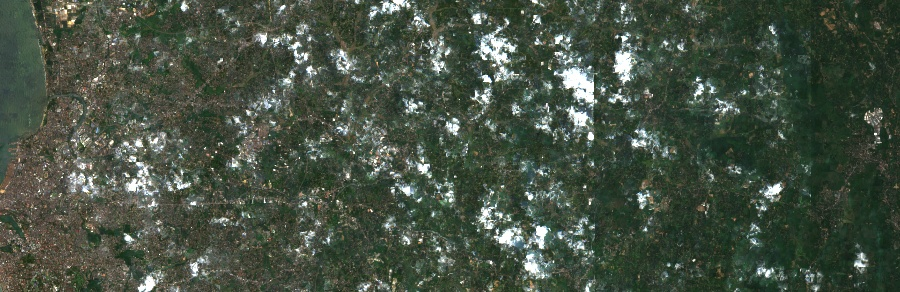


 step02_s1_post_vv.png


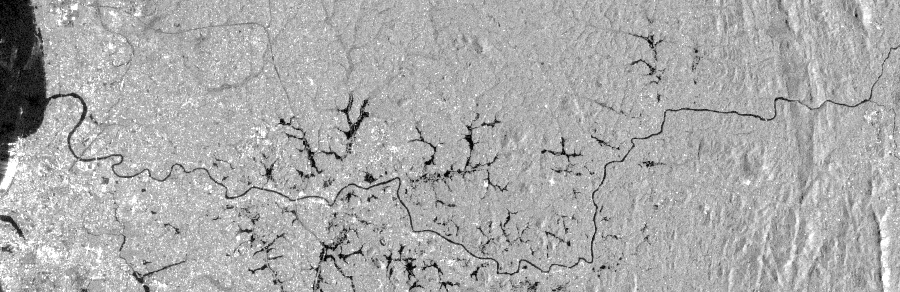


Saved to /content/drive/MyDrive/M1_Research/records


In [1]:
# ===== M1 Step 2: GEE data availability check — Kelani basin, Cyclone Ditwah =====
!pip -q install earthengine-api
import ee, json, os, requests, datetime
from IPython.display import Image, display
from google.colab import drive
drive.mount('/content/drive')

PROJECT_ID = 'sliit-research-2026'      # <-- change this
ee.Authenticate()
ee.Initialize(project=PROJECT_ID)

# Lower Kelani basin box (Colombo coast -> Avissawella). [west, south, east, north]
AOI = ee.Geometry.Rectangle([79.85, 6.90, 80.22, 7.02])
rec = {"step": 2, "time": datetime.datetime.now().isoformat(), "aoi": [79.85, 6.90, 80.22, 7.02]}

# 1) PRE-flood Sentinel-2 (dry-ish months 2025, low cloud)
s2 = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
        .filterBounds(AOI).filterDate('2025-01-01', '2025-10-31')
        .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20)))
rec["s2_pre_count"] = s2.size().getInfo()
best = s2.sort('CLOUDY_PIXEL_PERCENTAGE').limit(5)
rec["s2_clearest"] = best.aggregate_array('system:index').getInfo()
rec["s2_clearest_cloud%"] = best.aggregate_array('CLOUDY_PIXEL_PERCENTAGE').getInfo()

# 2) POST-flood Sentinel-1 SAR (Ditwah) + a PRE-flood SAR reference
def s1(start, end):
    return (ee.ImageCollection('COPERNICUS/S1_GRD').filterBounds(AOI)
              .filterDate(start, end)
              .filter(ee.Filter.eq('instrumentMode', 'IW'))
              .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV')))
s1_post = s1('2025-11-26', '2025-12-10')
s1_pre  = s1('2025-10-01', '2025-11-20')
rec["s1_post_dates"] = sorted(set(d[:10] for d in s1_post.aggregate_array('system:time_start')
                         .map(lambda t: ee.Date(t).format('YYYY-MM-dd')).getInfo()))
rec["s1_pre_dates"]  = sorted(set(d[:10] for d in s1_pre.aggregate_array('system:time_start')
                         .map(lambda t: ee.Date(t).format('YYYY-MM-dd')).getInfo()))
rec["s1_post_orbit"] = s1_post.aggregate_array('orbitProperties_pass').distinct().getInfo()

# 3) Building footprints (Google Open Buildings v3)
blds = (ee.FeatureCollection('GOOGLE/Research/open-buildings/v3/polygons')
          .filterBounds(AOI).filter(ee.Filter.gte('confidence', 0.75)))
rec["buildings_conf>=0.75"] = blds.size().getInfo()

# 4) Elevation (SRTM 30 m)
dem = ee.Image('USGS/SRTMGL1_003')
rec["dem_stats_m"] = dem.reduceRegion(ee.Reducer.minMax(), AOI, 30, maxPixels=1e9).getInfo()

for k, v in rec.items(): print(f"{k:22s}: {v}")

# 5) Save evidence: two preview images + JSON record
OUT = '/content/drive/MyDrive/M1_Research/records'; os.makedirs(OUT, exist_ok=True)
pre_rgb = s2.median().clip(AOI)
url1 = pre_rgb.getThumbURL({'bands': ['B4','B3','B2'], 'min': 0, 'max': 3000, 'dimensions': 900, 'region': AOI})
if rec["s1_post_dates"]:
    post_vv = s1_post.select('VV').min().clip(AOI)   # min = darkest = most water
    url2 = post_vv.getThumbURL({'min': -25, 'max': 0, 'dimensions': 900, 'region': AOI})
else:
    url2 = None
for name, url in [('step02_s2_pre_rgb.png', url1), ('step02_s1_post_vv.png', url2)]:
    if url:
        open(f'{OUT}/{name}', 'wb').write(requests.get(url).content)
        print("\n", name); display(Image(f'{OUT}/{name}'))
json.dump(rec, open(f'{OUT}/step02_gee_check.json', 'w'), indent=2)
print("\nSaved to", OUT)

S2 scenes used (all, before pixel masking): 140
Kolonnawa/Wellampitiya    buildings: 3882
Kaduwela                  buildings: 2143
Malwana                   buildings: 2040
Hanwella                  buildings: 1307
Avissawella side          buildings: 1359


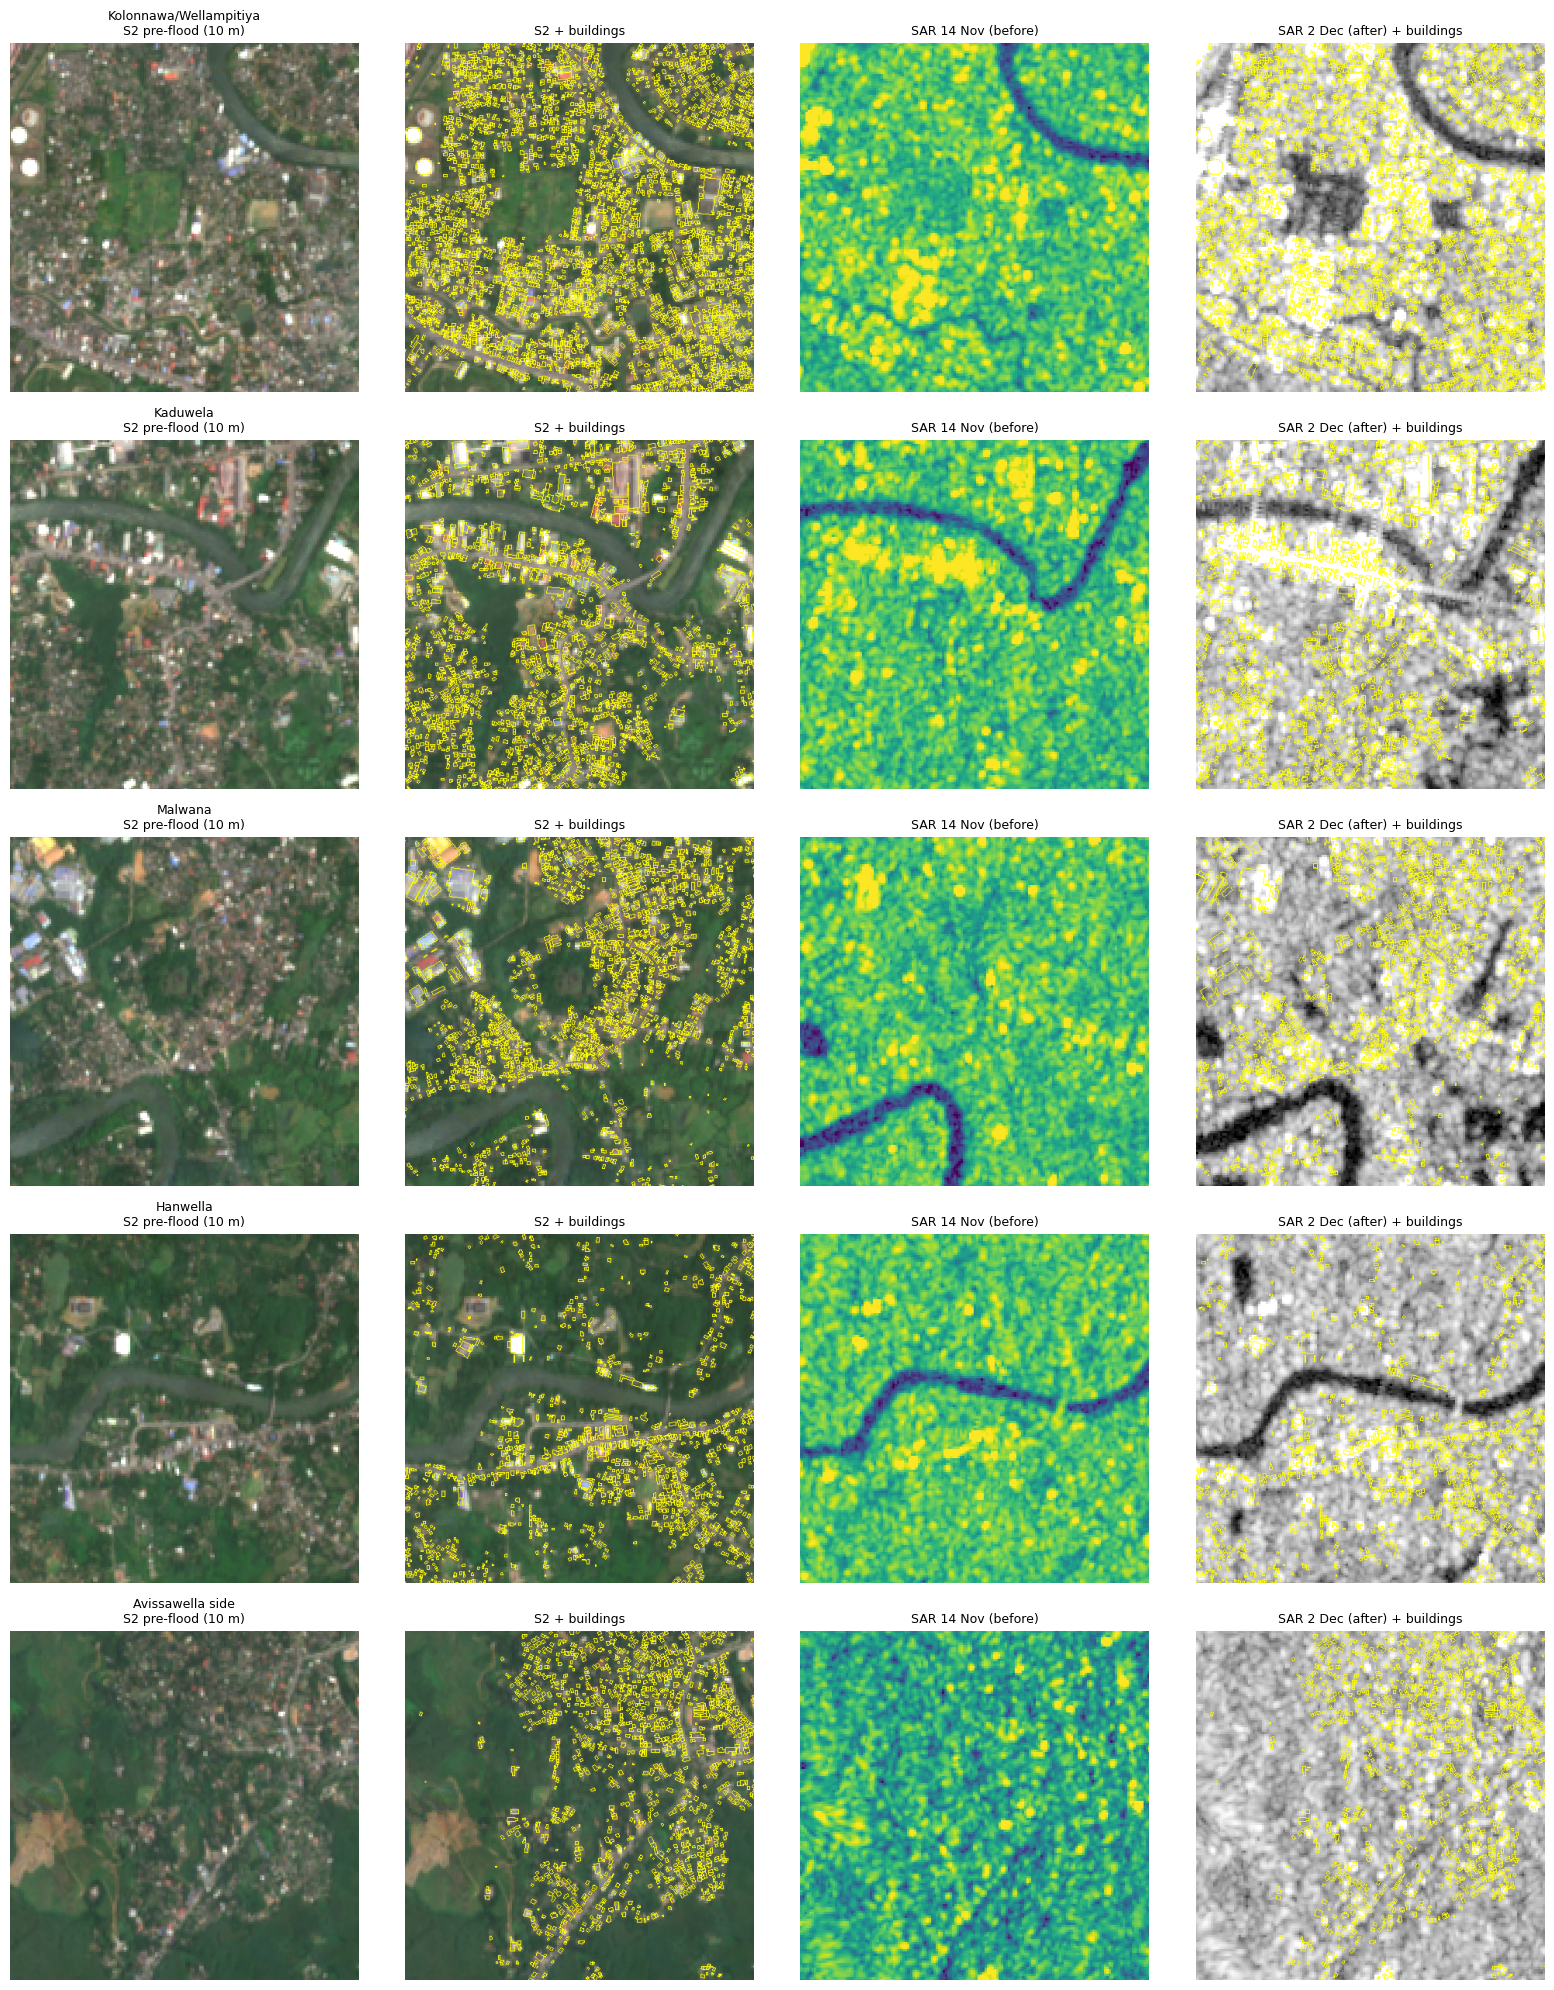

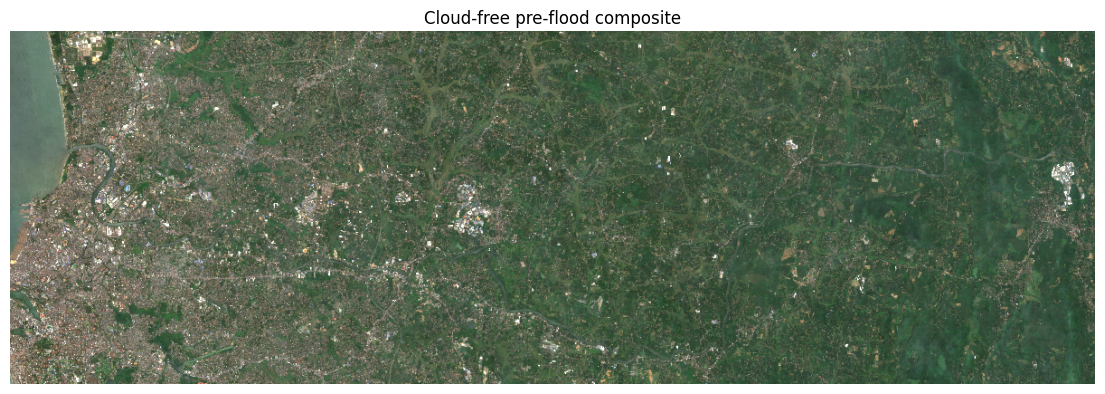

Saved to /content/drive/MyDrive/M1_Research/records


In [2]:
# ===== M1 Step 3: Cloud-free S2 composite + zoomed tiles with buildings & SAR flood =====
import ee, os, io, json, requests, datetime
import matplotlib.pyplot as plt
from PIL import Image as PILImage

PROJECT_ID = 'sliit-research-2026'
try:
    ee.Initialize(project=PROJECT_ID)
except Exception:
    ee.Authenticate(auth_mode='notebook'); ee.Initialize(project=PROJECT_ID)

AOI = ee.Geometry.Rectangle([79.85, 6.90, 80.22, 7.02])
OUT = '/content/drive/MyDrive/M1_Research/records'; os.makedirs(OUT, exist_ok=True)

# 1) Cloud-free Sentinel-2 using Cloud Score+ (pixel-level cloud removal)
cs = ee.ImageCollection('GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED')
s2_all = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
            .filterBounds(AOI).filterDate('2025-01-01', '2025-10-31')
            .linkCollection(cs, ['cs_cdf']))
s2_clean = (s2_all.map(lambda img: img.updateMask(img.select('cs_cdf').gte(0.60)))
                  .select(['B2', 'B3', 'B4', 'B8']).median())
print("S2 scenes used (all, before pixel masking):", s2_all.size().getInfo())

# 2) SAR before (14 Nov) and after (2 Dec) — same orbit (DESCENDING) so they are comparable
def s1_day(day):
    d = ee.Date(day)
    return (ee.ImageCollection('COPERNICUS/S1_GRD').filterBounds(AOI)
              .filterDate(d, d.advance(1, 'day'))
              .filter(ee.Filter.eq('instrumentMode', 'IW'))
              .select('VV').mosaic())
sar_before, sar_after = s1_day('2025-11-14'), s1_day('2025-12-02')

# 3) Buildings
blds = (ee.FeatureCollection('GOOGLE/Research/open-buildings/v3/polygons')
          .filterBounds(AOI).filter(ee.Filter.gte('confidence', 0.75)))
outline = ee.Image().byte().paint(featureCollection=blds, color=1, width=1).visualize(palette=['ffff00'])

# 4) Visual layers
rgb_vis  = s2_clean.visualize(bands=['B4', 'B3', 'B2'], min=0, max=2500, gamma=1.2)
sarb_vis = sar_before.visualize(min=-25, max=0)
sara_vis = sar_after.visualize(min=-25, max=0)
layers = [("S2 pre-flood (10 m)", rgb_vis),
          ("S2 + buildings", rgb_vis.blend(outline)),
          ("SAR 14 Nov (before)", sarb_vis),
          ("SAR 2 Dec (after) + buildings", sara_vis.blend(outline))]

# 5) Five sample tiles along the Kelani (lon, lat) — 1.5 km x 1.5 km each
tiles = {"Kolonnawa/Wellampitiya": (79.895, 6.945),
         "Kaduwela":               (79.983, 6.935),
         "Malwana":                (80.015, 6.950),
         "Hanwella":               (80.080, 6.910),
         "Avissawella side":       (80.200, 6.953)}

def thumb(img, region, px=450):
    url = img.getThumbURL({'region': region, 'dimensions': px, 'format': 'png'})
    return PILImage.open(io.BytesIO(requests.get(url).content))

rec = {"step": 3, "time": datetime.datetime.now().isoformat(), "tile_building_counts": {}}
fig, axes = plt.subplots(len(tiles), 4, figsize=(16, 4 * len(tiles)))
for r, (name, (lon, lat)) in enumerate(tiles.items()):
    region = ee.Geometry.Point([lon, lat]).buffer(750).bounds()
    n = blds.filterBounds(region).size().getInfo()
    rec["tile_building_counts"][name] = n
    for c, (title, layer) in enumerate(layers):
        axes[r, c].imshow(thumb(layer, region)); axes[r, c].axis('off')
        axes[r, c].set_title(f"{name}\n{title}" if c == 0 else title, fontsize=9)
    print(f"{name:25s} buildings: {n}")
plt.tight_layout()
plt.savefig(f'{OUT}/step03_zoom_tiles.png', dpi=110); plt.show()

# 6) Also save the full cloud-free overview for comparison with Step 2
full = thumb(rgb_vis, AOI, 1200); full.save(f'{OUT}/step03_s2_cloudfree_full.png')
plt.figure(figsize=(14, 5)); plt.imshow(full); plt.axis('off'); plt.title("Cloud-free pre-flood composite"); plt.show()
json.dump(rec, open(f'{OUT}/step03_record.json', 'w'), indent=2)
print("Saved to", OUT)

Step 4: Create the flood map and a flooded / not-flooded label for every building